# Case file 2 · Fingerprints: what do all sprites have in common?

<a href="https://colab.research.google.com/github/umanets/pixelsprite/blob/main/learn/02_fingerprints.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

A detective compares a suspect with *random* people to see what is special. We do the same:
measure sprite shapes and compare them with two kinds of random shapes of the same size.

**Time:** about 1 minute. **You will learn:** connected pieces, holes, outlines, symmetry, and one number that
separates "drawn" from "random": perimeter / √area.

In [1]:
try:
    import pixelsprite
except ImportError:
    %pip -q install "pixelsprite[learn] @ git+https://github.com/umanets/pixelsprite"
import os, warnings
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")
warnings.filterwarnings("ignore")
from huggingface_hub.utils import logging as hf_logging
hf_logging.set_verbosity_error()

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from IPython.display import display
from pixelsprite import sheet, mask_rgba
from pixelsprite.data import load_shard

sprites = load_shard(n=3000, seed=0)
masks = sprites.mask                     # (N, 16, 16) True where the pixel is solid
print(masks.shape, "average area:", masks.sum((1, 2)).mean().round(1), "pixels")

(3000, 16, 16) average area: 155.7 pixels


## 1. Four measurements
* **pieces**: how many separate blobs. Two pixels belong together if they touch, even corner to corner (8 neighbours).
* **holes**: empty regions completely surrounded by the shape.
* **perimeter**: how many pixel edges separate the shape from the outside.
* **mirror match** (IoU): flip the shape left↔right and measure overlap ÷ union. 1.0 means perfectly symmetric.

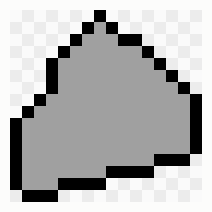

{'pieces': 1, 'holes': 0, 'compactness': np.float64(4.96736336452053), 'mirror': np.float64(0.7473684210526316)}


In [3]:
EIGHT = np.ones((3, 3), bool)                         # 8-neighbourhood
FOUR = ndi.generate_binary_structure(2, 1)            # 4-neighbourhood (up, down, left, right)

def crop(m):
    rows, cols = np.flatnonzero(m.any(1)), np.flatnonzero(m.any(0))
    return m[rows[0]:rows[-1] + 1, cols[0]:cols[-1] + 1]

def pieces(m):
    return ndi.label(m, structure=EIGHT)[1]

def holes(m):
    lab, n = ndi.label(~np.pad(m, 1), structure=FOUR)  # empty regions; the padded frame is "outside"
    return n - 1                                       # every empty region except the outside is a hole

def perimeter(m):
    p = np.pad(m, 1).astype(np.int8)
    return int(np.abs(np.diff(p, axis=0)).sum() + np.abs(np.diff(p, axis=1)).sum())

def mirror_iou(m):
    f = m[:, ::-1]
    return (m & f).sum() / (m | f).sum()

def measure(m):
    m = crop(m)
    return {"pieces": pieces(m), "holes": holes(m), "compactness": perimeter(m) / np.sqrt(m.sum()),
            "mirror": mirror_iou(m)}

# Try it on one sprite
m = masks[7]
display(sheet([mask_rgba(m)], scale=12, cols=1))
print(measure(m))

## 2. Random suspects of the same size
For every sprite we make two random shapes inside the same box with the same number of pixels:
* **random pixels**: scattered anywhere;
* **random blob**: grown from one pixel by adding random neighbours (always one connected piece).

In [4]:
rng = np.random.default_rng(0)

def random_pixels(h, w, area):
    flat = np.zeros(h * w, bool)
    flat[rng.choice(h * w, size=area, replace=False)] = True
    return flat.reshape(h, w)

def random_blob(h, w, area):
    m, queued = np.zeros((h, w), bool), np.zeros((h, w), bool)
    r, c = rng.integers(h), rng.integers(w)
    frontier, queued[r, c] = [(r, c)], True
    for _ in range(area):
        i = rng.integers(len(frontier))
        frontier[i], frontier[-1] = frontier[-1], frontier[i]
        r, c = frontier.pop()
        m[r, c] = True
        for rr, cc in ((r + 1, c), (r - 1, c), (r, c + 1), (r, c - 1)):
            if 0 <= rr < h and 0 <= cc < w and not queued[rr, cc]:
                queued[rr, cc] = True
                frontier.append((rr, cc))
    return m

rows = {"sprites": [], "random pixels": [], "random blob": []}
for m in masks:
    c = crop(m)
    h, w, a = *c.shape, int(c.sum())
    rows["sprites"].append(measure(c))
    rows["random pixels"].append(measure(random_pixels(h, w, a)))
    rows["random blob"].append(measure(random_blob(h, w, a)))

def share(rs, f):
    return 100 * np.mean([f(r) for r in rs])

print(f"{'':15} {'one piece':>10} {'no holes':>10} {'exact mirror':>13} {'compactness':>12}")
for name, rs in rows.items():
    print(f"{name:15} {share(rs, lambda r: r['pieces'] == 1):9.1f}% {share(rs, lambda r: r['holes'] == 0):9.1f}% "
          f"{share(rs, lambda r: r['mirror'] == 1):12.1f}% {np.median([r['compactness'] for r in rs]):12.2f}")

                 one piece   no holes  exact mirror  compactness
sprites              99.7%      86.4%         22.2%         5.37
random pixels        63.4%       0.2%          0.0%        17.94
random blob         100.0%       2.5%          0.0%         7.53


## 3. The best single clue: compactness
Perimeter ÷ √area does not depend on size (double the size: perimeter ×2, √area ×2).
A drawn object has a smooth outline, so the number is small.

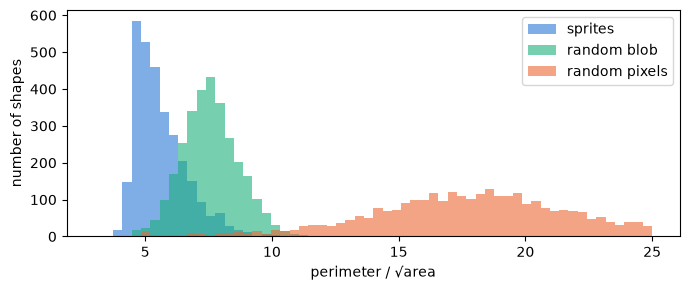

In [5]:
plt.figure(figsize=(7, 3))
for name, colour in (("sprites", "#2a78d6"), ("random blob", "#1baf7a"), ("random pixels", "#eb6834")):
    plt.hist([r["compactness"] for r in rows[name]], bins=60, range=(3, 25), alpha=0.6, label=name, color=colour)
plt.xlabel("perimeter / √area"); plt.ylabel("number of shapes"); plt.legend(); plt.tight_layout(); plt.show()

## 4. Symmetry depends on the object
Compare how often different objects are exactly mirror-symmetric.

In [6]:
more = load_shard(n=30000, seed=1)                       # a bigger sample, only the mirror test (fast)
for word in ["shield", "potion", "crown", "sword", "boot", "bird"]:
    sel = [mirror_iou(crop(m)) == 1 for m, c in zip(more.mask, more.subject) if word in c.split()]
    print(f"{word:8} {len(sel):5} sprites, exactly symmetric: {100 * np.mean(sel):5.1f}%")

shield     100 sprites, exactly symmetric:  73.0%
potion      52 sprites, exactly symmetric:  38.5%
crown       65 sprites, exactly symmetric:  66.2%
sword      174 sprites, exactly symmetric:  26.4%
boot        94 sprites, exactly symmetric:   0.0%
bird        62 sprites, exactly symmetric:  19.4%


## Your turn
1. Which sprites have more than one piece? Show them with `sheet([mask_rgba(m) for m in ...])`.
2. Invent your own measurement (for example, "how tall is the shape compared to its width") and compare it with the random suspects.